In [1]:
import cv2

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cbook import get_sample_data
from PIL import Image

In [2]:
def show_images(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 3.5), layout="constrained")
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.show()



image_path = get_sample_data("grace_hopper.jpg", asfileobj=False)
with Image.open(image_path) as source:
    image = np.asarray(source.convert("L"))

size = 5
sigma = 1.2
padding = cv2.BORDER_REPLICATE

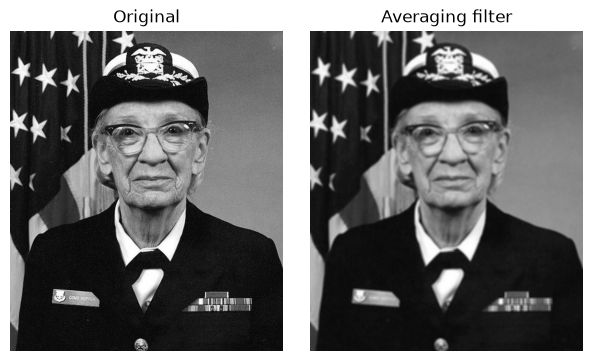

In [3]:
# Question 1
averaged = cv2.blur(image, (size, size), borderType=padding)
show_images((image, averaged), ("Original", "Averaging filter"))

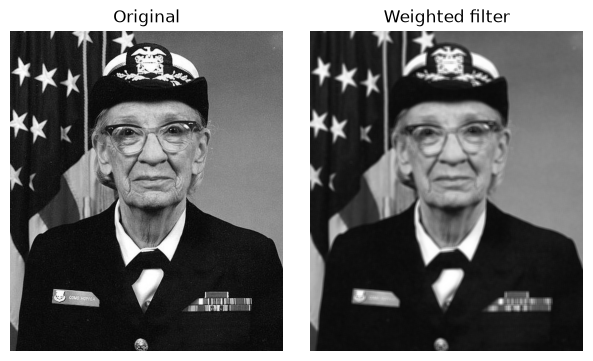

In [4]:
# Question 2
coordinates = np.abs(np.arange(size) - size // 2)
weights = np.maximum.outer(coordinates, coordinates).astype(float)
weights /= weights.sum()
weighted = cv2.filter2D(image, -1, weights, borderType=padding)
show_images((image, weighted), ("Original", "Weighted filter"))

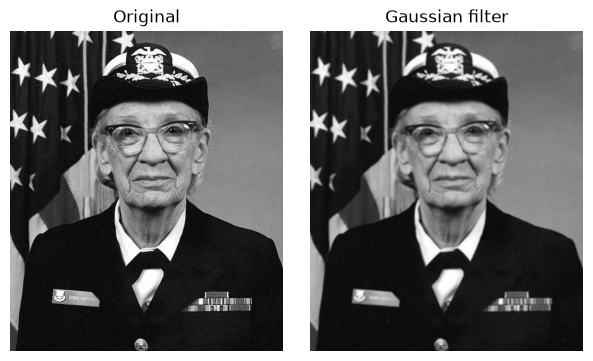

In [5]:
# Question 3
gaussian = cv2.GaussianBlur(image, (size, size), sigmaX=sigma, borderType=padding)
show_images((image, gaussian), ("Original", "Gaussian filter"))